# Experiment 8 — ANOVA Test

## Scenario: Coffee Shop Loyalty — Do Different Loyalty Programs Drive Different Spending?

A coffee chain runs **4 different loyalty programs** across its branches. The management wants to know if the type of loyalty program significantly affects the **average monthly spend per customer**.

| Group | Program | Description |
|---|---|---|
| A | No Program | Control — no rewards |
| B | Points-Based | Earn points per purchase |
| C | Subscription | Fixed monthly fee, perks included |
| D | Cashback | % of spend returned as credit |

**Dataset:** 120 customers — 30 per group  
**Metric:** Monthly spend (₹)  
**Test:** One-Way ANOVA → Post-hoc Tukey HSD  
**H₀:** All group means are equal (µA = µB = µC = µD)  
**H₁:** At least one group mean is different  
**α = 0.05**


In [6]:
# ── 0. Imports ─────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os, warnings
warnings.filterwarnings('ignore')

np.random.seed(7)
output_dir = os.getcwd()
ALPHA = 0.05
N_PER_GROUP = 30

print('Libraries loaded ✓')

Libraries loaded ✓


---
## 1. Dataset Generation

In [7]:
# ── 1. Generate Dataset ────────────────────────────────────────────────────────
# Monthly spend in ₹ per customer — different programs drive different spending

groups = {
    'No Program':    np.random.normal(loc=800,  scale=120, size=N_PER_GROUP),  # baseline
    'Points-Based':  np.random.normal(loc=950,  scale=130, size=N_PER_GROUP),  # mild lift
    'Subscription':  np.random.normal(loc=1200, scale=150, size=N_PER_GROUP),  # strong lift
    'Cashback':      np.random.normal(loc=1050, scale=140, size=N_PER_GROUP),  # moderate lift
}

records = []
cust_id = 1
for program, spends in groups.items():
    for spend in spends:
        records.append({
            'customer_id':   cust_id,
            'program':       program,
            'monthly_spend': round(max(spend, 100), 2)   # floor at ₹100
        })
        cust_id += 1

df = pd.DataFrame(records)

print(f'Dataset shape : {df.shape}')
print()
print(df.groupby('program')['monthly_spend'].agg(['count','mean','std']).round(2))
df.head(8)

Dataset shape : (120, 3)

              count     mean     std
program                             
Cashback         30  1074.35  122.61
No Program       30   791.23  121.28
Points-Based     30   948.91  147.27
Subscription     30  1204.63  150.90


,customer_id,program,monthly_spend
0,1,No Program,1002.86
1,2,No Program,744.09
2,3,No Program,803.94
3,4,No Program,848.90
4,5,No Program,705.33
5,6,No Program,800.25
6,7,No Program,799.89
7,8,No Program,589.43


In [8]:
# ── 1b. Save Dataset ───────────────────────────────────────────────────────────
df.to_csv(os.path.join(output_dir, 'anova_coffee_dataset.csv'), index=False)
print('Dataset saved → anova_coffee_dataset.csv ✓')

Dataset saved → anova_coffee_dataset.csv ✓


---
## 2. Assumptions Check
ANOVA requires: **(1) Normality** within groups, **(2) Homogeneity of Variance** across groups

In [9]:
# ── 2a. Normality — Shapiro-Wilk Test per group ────────────────────────────────
print('Shapiro-Wilk Normality Test (H₀: data is normally distributed)')
print('='*55)
norm_rows = []
for prog in df['program'].unique():
    data = df[df['program'] == prog]['monthly_spend']
    stat, p = stats.shapiro(data)
    result = 'Normal ✓' if p > ALPHA else 'Non-normal ✗'
    norm_rows.append({'Program': prog, 'W-stat': round(stat,4), 'p-value': round(p,4), 'Result': result})
    print(f'  {prog:<18} W={stat:.4f}  p={p:.4f}  → {result}')

print()

# ── 2b. Homogeneity of Variance — Levene's Test ────────────────────────────────
group_data = [df[df['program'] == p]['monthly_spend'].values for p in df['program'].unique()]
lev_stat, lev_p = stats.levene(*group_data)
print('Levene Test for Equal Variances (H₀: all group variances are equal)')
print('='*55)
print(f'  Levene statistic : {lev_stat:.4f}')
print(f'  p-value          : {lev_p:.4f}')
print(f'  Result           : {"Equal variances ✓" if lev_p > ALPHA else "Unequal variances ✗"}')

Shapiro-Wilk Normality Test (H₀: data is normally distributed)
  No Program         W=0.9744  p=0.6658  → Normal ✓
  Points-Based       W=0.9797  p=0.8167  → Normal ✓
  Subscription       W=0.9588  p=0.2894  → Normal ✓
  Cashback           W=0.9735  p=0.6385  → Normal ✓

Levene Test for Equal Variances (H₀: all group variances are equal)
  Levene statistic : 0.9855
  p-value          : 0.4023
  Result           : Equal variances ✓


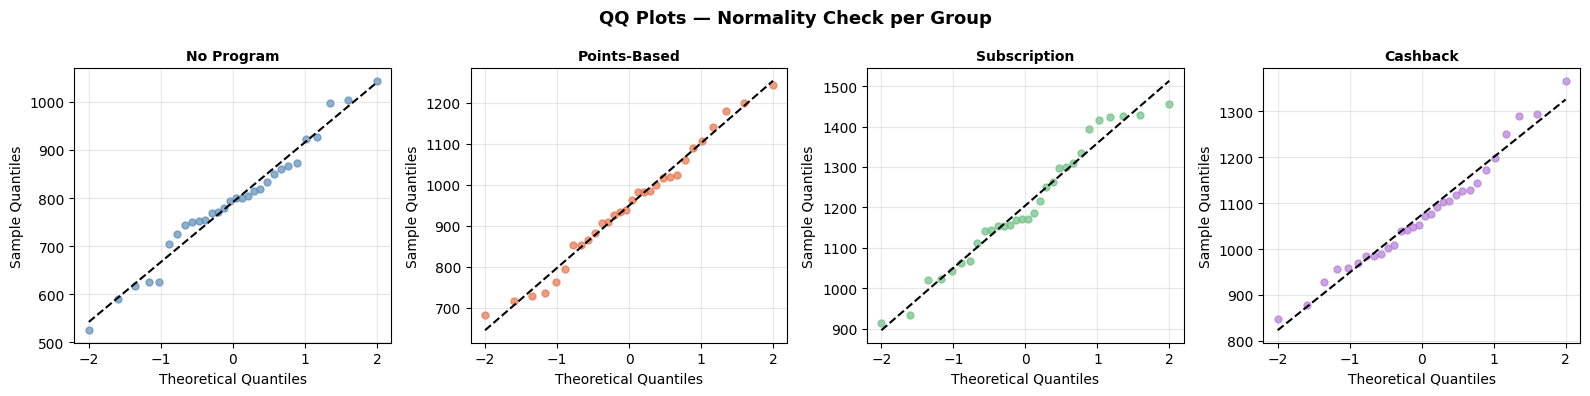

In [10]:
# ── 2c. QQ Plots — visual normality check ─────────────────────────────────────
programs = df['program'].unique()
colors_map = {'No Program': '#5B8DB8', 'Points-Based': '#E8734A',
              'Subscription': '#6DBF82', 'Cashback': '#B57BDB'}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle('QQ Plots — Normality Check per Group', fontsize=13, fontweight='bold')

for ax, prog in zip(axes, programs):
    data = df[df['program'] == prog]['monthly_spend']
    (osm, osr), (slope, intercept, r) = stats.probplot(data, dist='norm')
    ax.scatter(osm, osr, color=colors_map[prog], alpha=0.7, s=25)
    ax.plot(osm, slope * np.array(osm) + intercept, 'k--', lw=1.5)
    ax.set_title(prog, fontsize=10, fontweight='bold')
    ax.set_xlabel('Theoretical Quantiles'); ax.set_ylabel('Sample Quantiles')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'anova_qq_plots.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 3. One-Way ANOVA

In [11]:
# ── 3. One-Way ANOVA ───────────────────────────────────────────────────────────
f_stat, p_val = stats.f_oneway(*group_data)

# Effect size — Eta-squared (η²)
grand_mean = df['monthly_spend'].mean()
ss_between = sum(N_PER_GROUP * (df[df['program']==p]['monthly_spend'].mean() - grand_mean)**2
                 for p in programs)
ss_total   = sum((df['monthly_spend'] - grand_mean)**2)
eta_sq     = ss_between / ss_total

print('='*58)
print('  ONE-WAY ANOVA RESULT — Coffee Loyalty Programs')
print('='*58)
print(f'  H₀ : µ_NoProgram = µ_Points = µ_Subscription = µ_Cashback')
print(f'  H₁ : At least one group mean differs')
print(f'  Significance level α = {ALPHA}')
print('-'*58)
print(f'  F-statistic  : {f_stat:.4f}')
print(f'  p-value      : {p_val:.6f}')
print(f'  Eta-squared  : {eta_sq:.4f}  ({"small" if eta_sq<0.06 else "medium" if eta_sq<0.14 else "large"} effect)')
print('-'*58)
if p_val < ALPHA:
    print(f'  ✅ REJECT H₀ — Significant difference exists between groups')
    print(f'  At least one loyalty program drives different spending.')
else:
    print(f'  ❌ FAIL TO REJECT H₀ — No significant difference found')
print('='*58)

  ONE-WAY ANOVA RESULT — Coffee Loyalty Programs
  H₀ : µ_NoProgram = µ_Points = µ_Subscription = µ_Cashback
  H₁ : At least one group mean differs
  Significance level α = 0.05
----------------------------------------------------------
  F-statistic  : 50.4077
  p-value      : 0.000000
  Eta-squared  : 0.5659  (large effect)
----------------------------------------------------------
  ✅ REJECT H₀ — Significant difference exists between groups
  At least one loyalty program drives different spending.


In [12]:
# ── 4. ANOVA Summary Table (SS, df, MS, F) ────────────────────────────────────
k          = len(programs)          # number of groups
N          = len(df)                # total observations
df_between = k - 1
df_within  = N - k
df_total   = N - 1

ss_within  = ss_total - ss_between
ms_between = ss_between / df_between
ms_within  = ss_within  / df_within
f_check    = ms_between / ms_within

anova_table = pd.DataFrame({
    'Source':     ['Between Groups (Treatment)', 'Within Groups (Error)', 'Total'],
    'SS':         [round(ss_between,2), round(ss_within,2), round(ss_total,2)],
    'df':         [df_between, df_within, df_total],
    'MS':         [round(ms_between,2), round(ms_within,2), '—'],
    'F-stat':     [round(f_check,4), '—', '—'],
    'p-value':    [round(p_val,6), '—', '—'],
    'Decision':   ['Reject H₀ ✅' if p_val < ALPHA else 'Do not reject H₀', '—', '—']
})

(anova_table.style
 .set_caption('ANOVA Summary Table')
 .set_properties(**{'text-align':'center','padding':'7px 14px','border':'1px solid #ddd'})
 .set_table_styles([{'selector':'th','props':'background-color:#2c3e50;color:white;text-align:center;padding:8px;'},
                    {'selector':'caption','props':'font-size:13px;font-weight:bold;padding-bottom:6px;'}])
 .apply(lambda x: ['background-color:#d4edda' if 'Reject' in str(v) else '' for v in x], axis=0)
)

,Source,SS,df,MS,F-stat,p-value,Decision
0,Between Groups (Treatment),2805131.350000,3,935043.780000,50.407700,0.000000,Reject H₀ ✅
1,Within Groups (Error),2151754.940000,116,18549.610000,—,—,—
2,Total,4956886.280000,119,—,—,—,—


---
## 4. Post-Hoc Test — Tukey HSD
ANOVA tells us *that* a difference exists — Tukey HSD tells us *which pairs* are different.

In [13]:
# ── 5. Tukey HSD Post-Hoc Test ────────────────────────────────────────────────
tukey = pairwise_tukeyhsd(endog=df['monthly_spend'], groups=df['program'], alpha=ALPHA)

tukey_df = pd.DataFrame(data=tukey._results_table.data[1:],
                        columns=tukey._results_table.data[0])
tukey_df.columns = ['Group 1', 'Group 2', 'Mean Diff', 'p-adj', 'CI Lower', 'CI Upper', 'Reject H₀']
tukey_df['Mean Diff'] = tukey_df['Mean Diff'].round(2)
tukey_df['p-adj']     = tukey_df['p-adj'].round(4)
tukey_df['CI Lower']  = tukey_df['CI Lower'].round(2)
tukey_df['CI Upper']  = tukey_df['CI Upper'].round(2)

def highlight_tukey(row):
    color = '#d4edda' if row['Reject H₀'] == True else ''
    return [f'background-color: {color}'] * len(row)

(tukey_df.style
 .apply(highlight_tukey, axis=1)
 .set_caption('Tukey HSD Post-Hoc — Pairwise Comparisons (green = significant difference)')
 .set_properties(**{'text-align':'center','padding':'7px 14px','border':'1px solid #ddd'})
 .set_table_styles([{'selector':'th','props':'background-color:#2c3e50;color:white;text-align:center;padding:8px;'},
                    {'selector':'caption','props':'font-size:13px;font-weight:bold;padding-bottom:6px;'}])
)

,Group 1,Group 2,Mean Diff,p-adj,CI Lower,CI Upper,Reject H₀
0,Cashback,No Program,-283.110000,0.000000,-374.780000,-191.450000,True
1,Cashback,Points-Based,-125.430000,0.002900,-217.100000,-33.770000,True
2,Cashback,Subscription,130.290000,0.001800,38.620000,221.950000,True
3,No Program,Points-Based,157.680000,0.000100,66.010000,249.340000,True
4,No Program,Subscription,413.400000,0.000000,321.730000,505.070000,True
5,Points-Based,Subscription,255.720000,0.000000,164.060000,347.390000,True


---
## 5. Visualisations

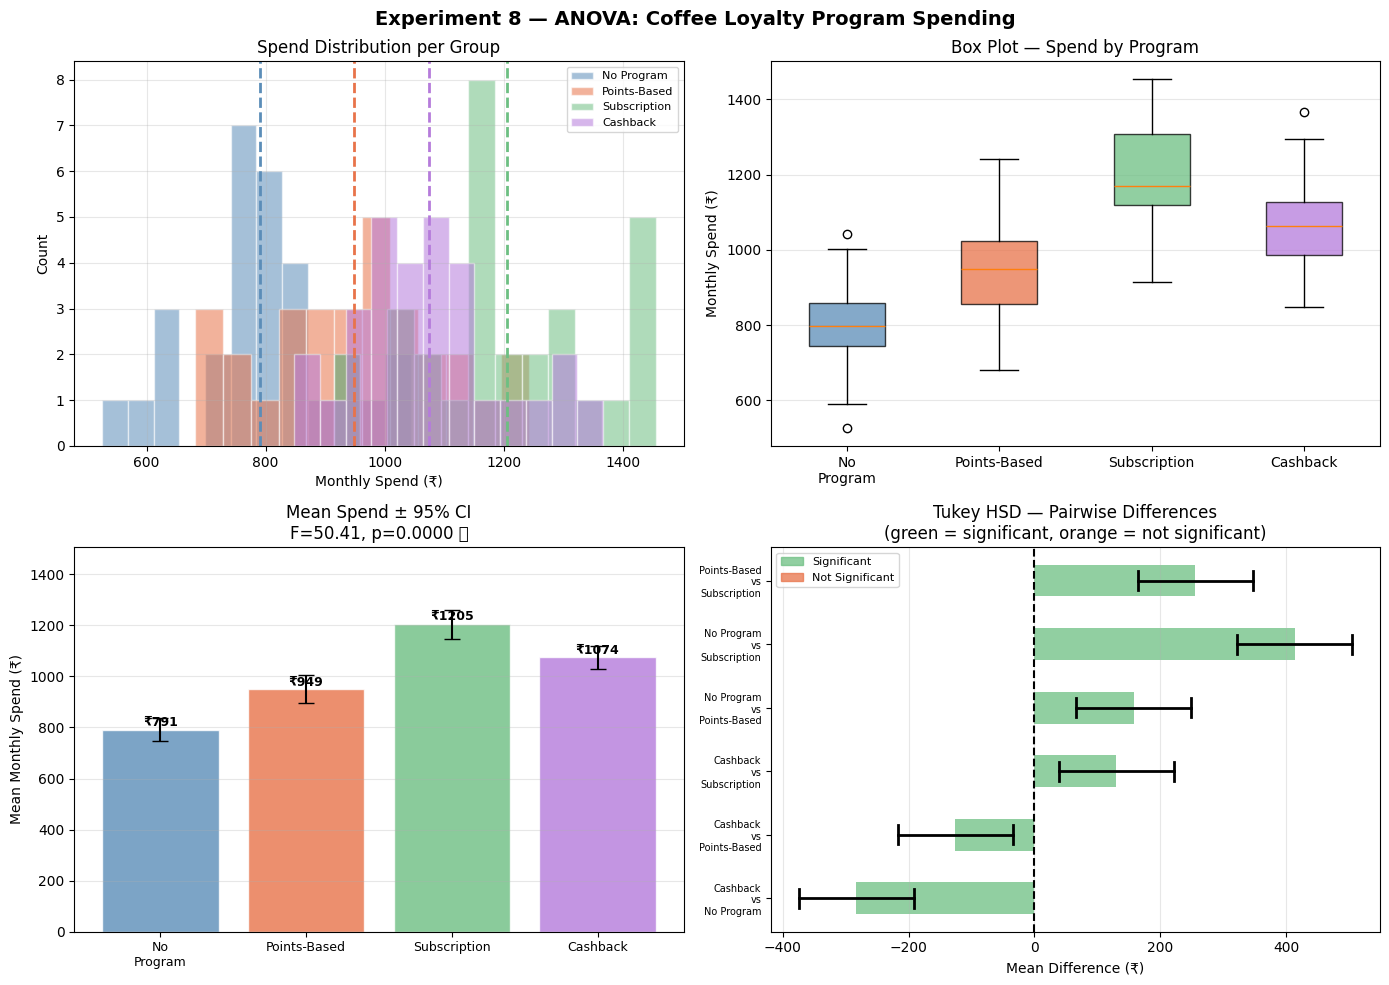

Plot saved → anova_results.png ✓


In [14]:
# ── 6. Four-panel visualisation ────────────────────────────────────────────────
palette = ['#5B8DB8', '#E8734A', '#6DBF82', '#B57BDB']
prog_list = list(programs)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Experiment 8 — ANOVA: Coffee Loyalty Program Spending', fontsize=14, fontweight='bold')

# ── Plot 1: Overlapping histograms ─────────────────────────────────────────────
ax = axes[0, 0]
for prog, col in zip(prog_list, palette):
    data = df[df['program'] == prog]['monthly_spend']
    ax.hist(data, bins=12, alpha=0.55, color=col, label=prog, edgecolor='white')
    ax.axvline(data.mean(), color=col, lw=2, ls='--')
ax.set_title('Spend Distribution per Group'); ax.set_xlabel('Monthly Spend (₹)'); ax.set_ylabel('Count')
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# ── Plot 2: Box plots ──────────────────────────────────────────────────────────
ax2 = axes[0, 1]
group_arrays = [df[df['program'] == p]['monthly_spend'].values for p in prog_list]
bp = ax2.boxplot(group_arrays, labels=[p.replace(' ', '\n') for p in prog_list],
                 patch_artist=True, widths=0.5, notch=False)
for patch, col in zip(bp['boxes'], palette):
    patch.set_facecolor(col); patch.set_alpha(0.75)
ax2.set_title('Box Plot — Spend by Program'); ax2.set_ylabel('Monthly Spend (₹)')
ax2.grid(alpha=0.3, axis='y')

# ── Plot 3: Mean ± 95% CI bar chart ───────────────────────────────────────────
ax3 = axes[1, 0]
means  = [df[df['program'] == p]['monthly_spend'].mean() for p in prog_list]
sems   = [stats.sem(df[df['program'] == p]['monthly_spend']) for p in prog_list]
t_crit = stats.t.ppf(1 - ALPHA/2, df=N_PER_GROUP - 1)
cis    = [se * t_crit for se in sems]
bars   = ax3.bar(prog_list, means, yerr=cis, capsize=6, color=palette, alpha=0.8, edgecolor='white')
for bar, mean in zip(bars, means):
    ax3.text(bar.get_x() + bar.get_width()/2, mean + 15, f'₹{mean:.0f}',
             ha='center', fontweight='bold', fontsize=9)
ax3.set_title(f'Mean Spend ± 95% CI\nF={f_stat:.2f}, p={p_val:.4f} ✅' if p_val < ALPHA
              else f'Mean Spend ± 95% CI\nF={f_stat:.2f}, p={p_val:.4f} ❌')
ax3.set_ylabel('Mean Monthly Spend (₹)')
ax3.set_xticklabels([p.replace(' ', '\n') for p in prog_list], fontsize=9)
ax3.set_ylim(0, max(means) * 1.25); ax3.grid(alpha=0.3, axis='y')

# ── Plot 4: Tukey HSD — Mean difference CI plot ────────────────────────────────
ax4 = axes[1, 1]
pairs      = [f"{r['Group 1']}\nvs\n{r['Group 2']}" for _, r in tukey_df.iterrows()]
diffs      = tukey_df['Mean Diff'].values.astype(float)
ci_lows    = tukey_df['CI Lower'].values.astype(float)
ci_highs   = tukey_df['CI Upper'].values.astype(float)
rejects    = tukey_df['Reject H₀'].values
y_pos      = np.arange(len(pairs))
bar_colors = ['#6DBF82' if r else '#E8734A' for r in rejects]

ax4.barh(y_pos, diffs, color=bar_colors, alpha=0.75, height=0.5)
for i, (d, lo, hi) in enumerate(zip(diffs, ci_lows, ci_highs)):
    ax4.plot([lo, hi], [i, i], 'k-', lw=2)
    ax4.plot([lo, lo], [i-0.15, i+0.15], 'k-', lw=2)
    ax4.plot([hi, hi], [i-0.15, i+0.15], 'k-', lw=2)
ax4.axvline(0, color='black', lw=1.5, ls='--')
ax4.set_yticks(y_pos); ax4.set_yticklabels(pairs, fontsize=7)
ax4.set_xlabel('Mean Difference (₹)')
ax4.set_title('Tukey HSD — Pairwise Differences\n(green = significant, orange = not significant)')
green_p = mpatches.Patch(color='#6DBF82', alpha=0.75, label='Significant')
orange_p = mpatches.Patch(color='#E8734A', alpha=0.75, label='Not Significant')
ax4.legend(handles=[green_p, orange_p], fontsize=8)
ax4.grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'anova_results.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved → anova_results.png ✓')

---
## 6. Final Summary

In [15]:
# ── 7. Final Summary Table ─────────────────────────────────────────────────────
summary_df = df.groupby('program')['monthly_spend'].agg(
    N='count', Mean='mean', Std='std', Min='min', Max='max'
).round(2).reset_index()
summary_df.columns = ['Program', 'N', 'Mean Spend (₹)', 'Std Dev', 'Min', 'Max']

footer = pd.DataFrame([{
    'Program': '── ANOVA Result ──',
    'N': f'F = {f_stat:.4f}',
    'Mean Spend (₹)': f'p = {p_val:.6f}',
    'Std Dev': f'η² = {eta_sq:.4f}',
    'Min': 'Reject H₀ ✅' if p_val < ALPHA else 'Do not reject H₀',
    'Max': 'Significant' if p_val < ALPHA else 'Not Significant'
}])
summary_df = pd.concat([summary_df, footer], ignore_index=True)

(summary_df.style
 .set_caption('Experiment 8 — ANOVA Final Summary')
 .set_properties(**{'text-align':'center','padding':'7px 14px','border':'1px solid #ddd'})
 .set_table_styles([{'selector':'th','props':'background-color:#2c3e50;color:white;text-align:center;padding:8px;'},
                    {'selector':'caption','props':'font-size:14px;font-weight:bold;padding-bottom:8px;'}])
)

,Program,N,Mean Spend (₹),Std Dev,Min,Max
0,Cashback,30,1074.350000,122.610000,847.960000,1366.390000
1,No Program,30,791.230000,121.280000,525.400000,1043.490000
2,Points-Based,30,948.910000,147.270000,681.630000,1242.190000
3,Subscription,30,1204.630000,150.900000,914.040000,1454.930000
4,── ANOVA Result ──,F = 50.4077,p = 0.000000,η² = 0.5659,Reject H₀ ✅,Significant


---
## 📚 ANOVA Quick Reference

| Term | Meaning |
|---|---|
| **F-statistic** | Ratio of variance between groups to variance within groups |
| **p-value < 0.05** | At least one group mean is significantly different |
| **η² (Eta-squared)** | Effect size: 0.01=small, 0.06=medium, 0.14=large |
| **Tukey HSD** | Post-hoc test — identifies *which specific pairs* differ |
| **SS Between** | Variance explained by the grouping factor |
| **SS Within** | Unexplained variance (random noise within groups) |
| **Shapiro-Wilk** | Tests normality within each group (p>0.05 = normal) |
| **Levene's Test** | Tests equal variances across groups (p>0.05 = equal) |

> **When ANOVA is significant → always run a post-hoc test.**  
> ANOVA only tells you *that* a difference exists, not *where* it is.